# PPG Frame Explorer

Interactive viewer for pipeline-exported frame CSVs. Each frame has 100 resampled samples (`sample_index_in_frame` 0-99).

Use the controls below to:
- Pick a **frame** by `frame_number`
- Choose which **channel(s)** to plot (AC waveform columns)
- Optionally overlay **DC** levels as horizontal reference lines

See the **AC Range Across Frames** section at the bottom for peak-to-peak amplitude over all frames.

In [35]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipywidgets import Checkbox, Dropdown, IntSlider, interact
from slopes.misc import compute_saturation_from_epsilon_ratio

# ---------------------------------------------------------------------------
# Config  edit path if needed
# ---------------------------------------------------------------------------
CSV_PATH = Path("data\ppg_frames_patient3.csv")

CHANS = ["1","2","3","5"]
wl1_cols = [f"wl1_{suffix}" for suffix in CHANS ]
wl2_cols = [f"wl2_{suffix}" for suffix in CHANS ]
AC_COLS =  wl1_cols + wl2_cols

DC_COLS = [f"dc_{c}" for c in AC_COLS]

<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\p'
C:\conda_tmp\ipykernel_77436\1878509147.py:12: SyntaxWarning: invalid escape sequence '\p'
  CSV_PATH = Path("data\ppg_frames_patient3.csv")


In [36]:
print(f"Loading {CSV_PATH} ...")
df = pd.read_csv(CSV_PATH)

required = {"frame_number", "sample_index_in_frame", *AC_COLS}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"CSV is missing columns: {sorted(missing)}")

frame_numbers = np.sort(df["frame_number"].unique())
frames = {
    int(fn): grp.sort_values("sample_index_in_frame")
    for fn, grp in df.groupby("frame_number", sort=False)
}

print(f"Loaded {len(df):,} rows across {len(frame_numbers):,} frames")
print(f"Frame range: {frame_numbers[0]} - {frame_numbers[-1]}")

Loading data\ppg_frames_patient3.csv ...
Loaded 136,200 rows across 1,362 frames
Frame range: 0 - 1361


### Frame completeness check

Verify that `frame_number` is contiguous and each frame has the expected number of samples.

In [37]:
expected_frames = np.arange(frame_numbers[0], frame_numbers[-1] + 1)
missing_frames = np.setdiff1d(expected_frames, frame_numbers)

if len(missing_frames) == 0:
    print(
        f"No missing frames. All {len(expected_frames)} frames present "
        f"({frame_numbers[0]} - {frame_numbers[-1]})."
    )
else:
    print(f"Missing {len(missing_frames)} frame(s):")
    print(missing_frames)

expected_samples = int(df["sample_index_in_frame"].max()) + 1
samples_per_frame = df.groupby("frame_number")["sample_index_in_frame"].count()
incomplete_frames = samples_per_frame[samples_per_frame != expected_samples]

if incomplete_frames.empty:
    print(f"All frames have {expected_samples} samples.")
else:
    print(f"{len(incomplete_frames)} frame(s) with != {expected_samples} samples:")
    print(incomplete_frames)

df.head()

No missing frames. All 1362 frames present (0 - 1361).
All frames have 100 samples.


,experiment_id,frame_number,sample_index_in_frame,time,wl1_1,wl1_2,wl1_3,wl1_5,wl2_1,wl2_2,...,wl2_5,fSaO2,dc_wl1_1,dc_wl1_2,dc_wl1_3,dc_wl1_5,dc_wl2_1,dc_wl2_2,dc_wl2_3,dc_wl2_5
0,patient3,0,0,26.25000,-0.000148,-0.000077,-0.000044,-1.469705e-05,0.000572,0.000215,...,1.245547e-05,0.0,0.341265,0.199057,0.104631,0.027382,0.39472,0.165067,0.061671,0.009144
1,patient3,0,1,26.25425,-0.000093,-0.000044,-0.000025,-1.014650e-05,0.000464,0.000190,...,9.480501e-06,0.0,0.341265,0.199057,0.104631,0.027382,0.39472,0.165067,0.061671,0.009144
2,patient3,0,2,26.25850,-0.000038,-0.000011,-0.000007,-5.595956e-06,0.000357,0.000165,...,6.505531e-06,0.0,0.341265,0.199057,0.104631,0.027382,0.39472,0.165067,0.061671,0.009144
3,patient3,0,3,26.26275,0.000017,0.000022,0.000012,-1.046173e-06,0.000249,0.000140,...,3.531024e-06,0.0,0.341265,0.199057,0.104631,0.027382,0.39472,0.165067,0.061671,0.009144
4,patient3,0,4,26.26700,0.000041,0.000036,0.000020,9.568609e-07,0.000098,0.000092,...,-3.193312e-07,0.0,0.341265,0.199057,0.104631,0.027382,0.39472,0.165067,0.061671,0.009144


In [38]:
CHANNEL_OPTIONS = [("All channels", "all"), *((c, c) for c in AC_COLS)]

frame_slider = IntSlider(
    value=int(frame_numbers[0]),
    min=int(frame_numbers[0]),
    max=int(frame_numbers[-1]),
    step=1,
    description="Frame:",
    continuous_update=False,
)

channel_dropdown = Dropdown(
    options=CHANNEL_OPTIONS,
    value="wl1_1",
    description="Channel:",
)

show_dc_checkbox = Checkbox(
    value=False,
    description="Show DC levels",
)

In [39]:
def plot_frame(frame_number, channel, show_dc):
    frame_df = frames[int(frame_number)]
    x = frame_df["sample_index_in_frame"].to_numpy()

    channels = AC_COLS if channel == "all" else [channel]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for ch in channels:
        ax.plot(x, frame_df[ch].to_numpy(), linewidth=1.4, label=ch)
        if show_dc and f"dc_{ch}" in frame_df.columns:
            dc_val = float(frame_df[f"dc_{ch}"].iloc[0])
            ax.axhline(dc_val, linestyle="--", linewidth=0.9, alpha=0.55, label=f"{ch} DC")

    ax.set_xlabel("sample_index_in_frame")
    ax.set_ylabel("AC amplitude")
    ax.set_xlim(0, 99)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=8, ncol=2 if channel == "all" else 1)

    t0 = float(frame_df["time"].iloc[0]) if "time" in frame_df.columns else np.nan
    fsao2 = float(frame_df["fSaO2"].iloc[0]) if "fSaO2" in frame_df.columns else np.nan
    exp_id = frame_df["experiment_id"].iloc[0] if "experiment_id" in frame_df.columns else ""

    subtitle_parts = [
        f"experiment: {exp_id}" if exp_id else None,
        f"t0 = {t0:.2f} s" if np.isfinite(t0) else None,
        f"fSaO2 = {fsao2:.3f}" if np.isfinite(fsao2) else None,
    ]
    subtitle = "  |  ".join(p for p in subtitle_parts if p)
    ax.set_title(f"Frame {frame_number}" + (f"\n{subtitle}" if subtitle else ""), fontsize=11)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

# interact(
#     plot_frame,
#     frame_number=frame_slider,
#     channel=channel_dropdown,
#     show_dc=show_dc_checkbox,
# );

## Tips

- **Frame slider**: steps through `frame_number` (0-based). Each frame is 100 samples on the x-axis.
- **Channel**: pick one PPG channel or overlay all 10 (`wl1_*` and `wl2_*`).
- **Show DC**: draws the per-frame DC baseline for the selected channel(s).
- Change `CSV_PATH` in the first code cell to point at another exported frames file.

## AC Range Across Frames

For each frame and channel, **AC_range** is the peak-to-peak AC amplitude within that frame:

$$\text{AC\_range} = \max(\text{AC}) - \min(\text{AC})$$

The plot below shows AC_range vs. `timestamp` (middle-sample time) for every channel.

### Frame timestamps

Each row in `ac_range_df` is indexed by `timestamp`: the `time` at the middle sample of the frame (`sample_index_in_frame` index 49 for 100-sample frames). `frame_number` is not kept in the summary tables.

In [40]:
if "time" not in df.columns:
    raise ValueError("CSV is missing the 'time' column")

ac_range_df = (
    df.groupby("frame_number", sort=True)[AC_COLS]
    .agg(lambda s: s.max() - s.min())
    .reset_index()
)

ac_range_df["timestamp"] = (
    df.groupby("frame_number", sort=True)["time"]
    .apply(lambda t: t.iloc[(len(t) - 1) // 2])
    .to_numpy()
)

ac_range_df = ac_range_df.drop(columns=["frame_number"])
ac_range_df = ac_range_df[["timestamp", *AC_COLS]]

timestamps = ac_range_df["timestamp"].to_numpy()

print(f"timestamps: {len(timestamps)} values, {timestamps[0]:.3f} - {timestamps[-1]:.3f} s")
ac_range_df.head()

timestamps: 1362 values, 26.458 - 1172.483 s


,timestamp,wl1_1,wl1_2,wl1_3,wl1_5,wl2_1,wl2_2,wl2_3,wl2_5
0,26.458250,0.000426,0.000264,0.000142,0.000034,0.001156,0.000402,0.000176,0.000029
1,27.295750,0.000146,0.000081,0.000059,0.000022,0.000174,0.000076,0.000043,0.000009
2,28.133250,0.000099,0.000047,0.000036,0.000016,0.000118,0.000041,0.000027,0.000007
3,28.964625,0.000113,0.000060,0.000047,0.000019,0.000139,0.000061,0.000036,0.000008
4,29.802125,0.000119,0.000067,0.000052,0.000021,0.000161,0.000072,0.000042,0.000010


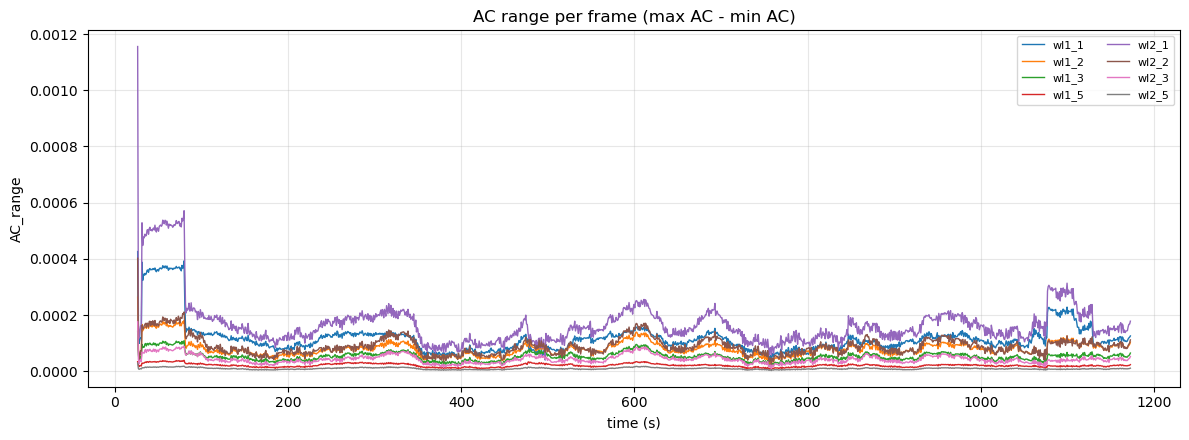

In [41]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for ch in AC_COLS:
    ax.plot(ac_range_df["timestamp"], ac_range_df[ch], linewidth=1.0, label=ch)

ax.set_xlabel("time (s)")
ax.set_ylabel("AC_range")
ax.set_title("AC range per frame (max AC - min AC)")
ax.legend(loc="upper right", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### AC + DC range dataframe

`ac_dc_range_df` copies `ac_range_df` and adds one DC value per channel per frame (`dc_wl1_*`, `dc_wl2_*`). DC is constant within a frame, so any sample row per frame gives the same value. Both tables use `timestamp` instead of `frame_number`.

In [42]:
missing_dc = set(DC_COLS) - set(df.columns)
if missing_dc:
    raise ValueError(f"CSV is missing DC columns: {sorted(missing_dc)}")


dc_per_frame_df = (
    df.groupby("frame_number", sort=True)[DC_COLS]
    .first()
    .reset_index(drop=True)
)
dc_per_frame_df["timestamp"]=ac_range_df["timestamp"].copy()

dc_per_frame_df.head()


,dc_wl1_1,dc_wl1_2,dc_wl1_3,dc_wl1_5,dc_wl2_1,dc_wl2_2,dc_wl2_3,dc_wl2_5,timestamp
0,0.341265,0.199057,0.104631,0.027382,0.394720,0.165067,0.061671,0.009144,26.458250
1,0.341962,0.199372,0.104765,0.027403,0.396001,0.165483,0.061814,0.009162,27.295750
2,0.342623,0.199639,0.104871,0.027416,0.396873,0.165738,0.061881,0.009166,28.133250
3,0.343453,0.199989,0.105021,0.027441,0.397955,0.166066,0.061977,0.009175,28.964625
4,0.344344,0.200375,0.105192,0.027472,0.399118,0.166430,0.062087,0.009187,29.802125


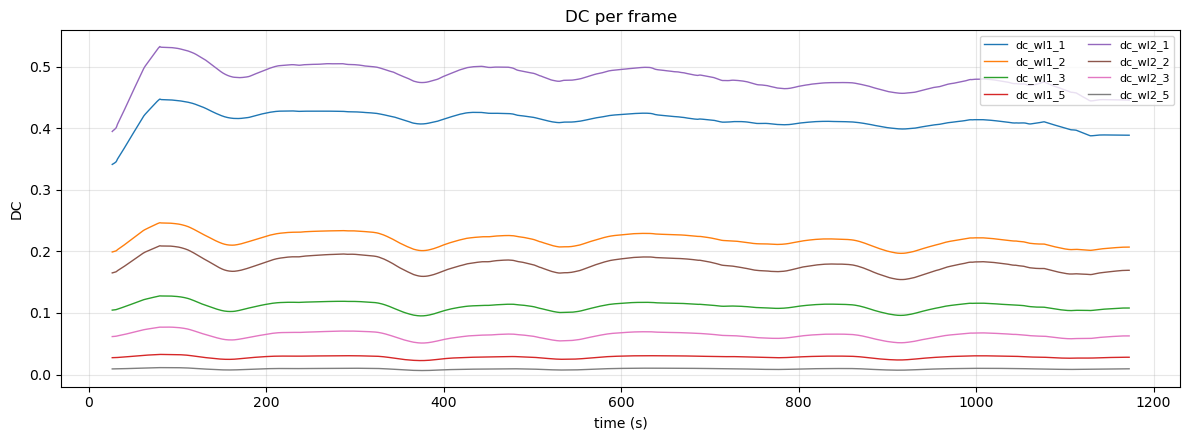

In [43]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for ch in DC_COLS:
    ax.plot(dc_per_frame_df["timestamp"], dc_per_frame_df[ch], linewidth=1.0, label=ch)

ax.set_xlabel("time (s)")
ax.set_ylabel("DC")
ax.set_title("DC per frame")
ax.legend(loc="upper right", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
ac_dc_range_df = ac_range_df.copy()
ac_dc_range_df[DC_COLS] = dc_per_frame_df[DC_COLS].to_numpy()

ac_dc_range_df.head()

,timestamp,wl1_1,wl1_2,wl1_3,wl1_5,wl2_1,wl2_2,wl2_3,wl2_5,dc_wl1_1,dc_wl1_2,dc_wl1_3,dc_wl1_5,dc_wl2_1,dc_wl2_2,dc_wl2_3,dc_wl2_5
0,26.458250,0.000426,0.000264,0.000142,0.000034,0.001156,0.000402,0.000176,0.000029,0.341265,0.199057,0.104631,0.027382,0.394720,0.165067,0.061671,0.009144
1,27.295750,0.000146,0.000081,0.000059,0.000022,0.000174,0.000076,0.000043,0.000009,0.341962,0.199372,0.104765,0.027403,0.396001,0.165483,0.061814,0.009162
2,28.133250,0.000099,0.000047,0.000036,0.000016,0.000118,0.000041,0.000027,0.000007,0.342623,0.199639,0.104871,0.027416,0.396873,0.165738,0.061881,0.009166
3,28.964625,0.000113,0.000060,0.000047,0.000019,0.000139,0.000061,0.000036,0.000008,0.343453,0.199989,0.105021,0.027441,0.397955,0.166066,0.061977,0.009175
4,29.802125,0.000119,0.000067,0.000052,0.000021,0.000161,0.000072,0.000042,0.000010,0.344344,0.200375,0.105192,0.027472,0.399118,0.166430,0.062087,0.009187


In [ ]:
# ##read from CSV

# CSV_PATH = Path("data/human_psa_ac_dc_per_sec_psa30_ma60.csv")
# ac_dc_range_df = pd.read_csv(CSV_PATH)
# ac_dc_range_df.head()

,sec_idx,timestamp,wl1_1,wl1_2,wl1_3,wl1_5,wl2_1,wl2_2,wl2_3,wl2_5,dc_wl1_1,dc_wl1_2,dc_wl1_3,dc_wl1_5,dc_wl2_1,dc_wl2_2,dc_wl2_3,dc_wl2_5
0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### EPR

For each frame (identified by `timestamp`) and wavelength channel, **EPR** is the peak-to-peak AC amplitude divided by the DC level:

$$\text{EPR} = \frac{\max(\text{AC}) - \min(\text{AC})}{\text{DC}}$$

`epr_df` has one row per timestamp and one column per wavelength (`wl1_*`, `wl2_*`).

In [45]:
epr_df = ac_dc_range_df[["timestamp"]].copy()
epr_df[AC_COLS] = (
    ac_dc_range_df[AC_COLS].to_numpy() / ac_dc_range_df[DC_COLS].to_numpy()
)

print(f"epr_df: {len(epr_df):,} rows x {len(AC_COLS)} channels")
print(f"Zero values: {(epr_df[AC_COLS] == 0).sum().sum():,}; NaN values: {epr_df[AC_COLS].isna().sum().sum():,}")
epr_df.head()

epr_df: 1,362 rows x 8 channels
Zero values: 0; NaN values: 0


,timestamp,wl1_1,wl1_2,wl1_3,wl1_5,wl2_1,wl2_2,wl2_3,wl2_5
0,26.458250,0.001248,0.001324,0.001354,0.001244,0.002928,0.002436,0.002854,0.003178
1,27.295750,0.000427,0.000405,0.000567,0.000813,0.000440,0.000461,0.000698,0.001030
2,28.133250,0.000289,0.000234,0.000343,0.000595,0.000297,0.000245,0.000433,0.000731
3,28.964625,0.000328,0.000300,0.000448,0.000709,0.000350,0.000368,0.000583,0.000901
4,29.802125,0.000345,0.000332,0.000490,0.000753,0.000403,0.000435,0.000680,0.001037


### log EPR

$$\text{log EPR} = \log (1+\frac{\max(\text{AC}) - \min(\text{AC})}{\text{DC}})$$

In [46]:
log_epr_df = epr_df[["timestamp"]].copy()

log_epr_df[AC_COLS] = np.log(1+epr_df[AC_COLS])

print(f"log_epr_df: {len(log_epr_df):,} rows x {len(AC_COLS)} channels")
print(f"Zero values: {(log_epr_df[AC_COLS] == 0).sum().sum():,}; NaN values: {log_epr_df[AC_COLS].isna().sum().sum():,}")
log_epr_df.head()

log_epr_df: 1,362 rows x 8 channels
Zero values: 0; NaN values: 0


,timestamp,wl1_1,wl1_2,wl1_3,wl1_5,wl2_1,wl2_2,wl2_3,wl2_5
0,26.458250,0.001248,0.001323,0.001353,0.001243,0.002924,0.002433,0.002850,0.003173
1,27.295750,0.000427,0.000405,0.000567,0.000813,0.000440,0.000461,0.000697,0.001030
2,28.133250,0.000289,0.000234,0.000343,0.000595,0.000297,0.000245,0.000433,0.000731
3,28.964625,0.000328,0.000300,0.000448,0.000709,0.000350,0.000368,0.000583,0.000901
4,29.802125,0.000345,0.000332,0.000490,0.000753,0.000403,0.000435,0.000680,0.001037


### Modulation ratio (MR)

For each detector pair, the modulation ratio (**MR**) is the wavelength-2 EPR divided by the wavelength-1 EPR:

$$\text{MR}_i = \frac{(\text{EPR})_{\text{wl1}_i}}{(\text{EPR})_{\text{wl2}_i}}, \quad i \in \{1, 2, 3, 5, 7\}$$


Zero MR values are treated as undefined and produce `NaN`.

In [47]:
mr_cols = [f"mr_{suffix}" for suffix in CHANS]

mr_df = epr_df[["timestamp"]].copy()
mr_df[mr_cols] = (
    epr_df[wl1_cols].to_numpy()
    / epr_df[wl2_cols].to_numpy()
)

print(f"Zero values: {(mr_df[mr_cols] == 0).sum().sum():,}; NaN values: {mr_df[mr_cols].isna().sum().sum():,}")

mr_df.replace(0, np.nan)


print(f"mr_df: {len(mr_df):,} rows x {len(mr_cols)} channels")
mr_df.head()

Zero values: 0; NaN values: 0
mr_df: 1,362 rows x 4 channels


,timestamp,mr_1,mr_2,mr_3,mr_5
0,26.458250,0.426366,0.543441,0.474351,0.391428
1,27.295750,0.970020,0.879599,0.812327,0.789382
2,28.133250,0.974301,0.956943,0.791982,0.813942
3,28.964625,0.937623,0.814902,0.768513,0.787377
4,29.802125,0.855999,0.763502,0.721237,0.726026


### Pulsation Ratio (PR)

$$\text{PR} = \frac{(\text{log EPR})_{\text{wl1}_i}}{(\text{log EPR})_{\text{wl2}_i}}, \quad i \in \{1, 2, 3, 5, 7\}$$

In [48]:
pr_cols = [f"pr_{suffix}" for suffix in CHANS]

pr_df = log_epr_df[["timestamp"]].copy()
pr_df[pr_cols] = (
    log_epr_df[wl1_cols].to_numpy()
    / log_epr_df[wl2_cols].to_numpy()
)

print(f"Zero values: {(pr_df[pr_cols] == 0).sum().sum():,}; NaN values: {pr_df[pr_cols].isna().sum().sum():,}")

pr_df.replace(0, np.nan)


print(f"mr_df: {len(pr_df):,} rows x {len(pr_cols)} channels")
pr_df.head()

Zero values: 0; NaN values: 0
mr_df: 1,362 rows x 4 channels


,timestamp,pr_1,pr_2,pr_3,pr_5
0,26.458250,0.426724,0.543743,0.474706,0.391806
1,27.295750,0.970026,0.879623,0.812380,0.789468
2,28.133250,0.974305,0.956948,0.792018,0.813997
3,28.964625,0.937634,0.814930,0.768565,0.787452
4,29.802125,0.856024,0.763541,0.721305,0.726129


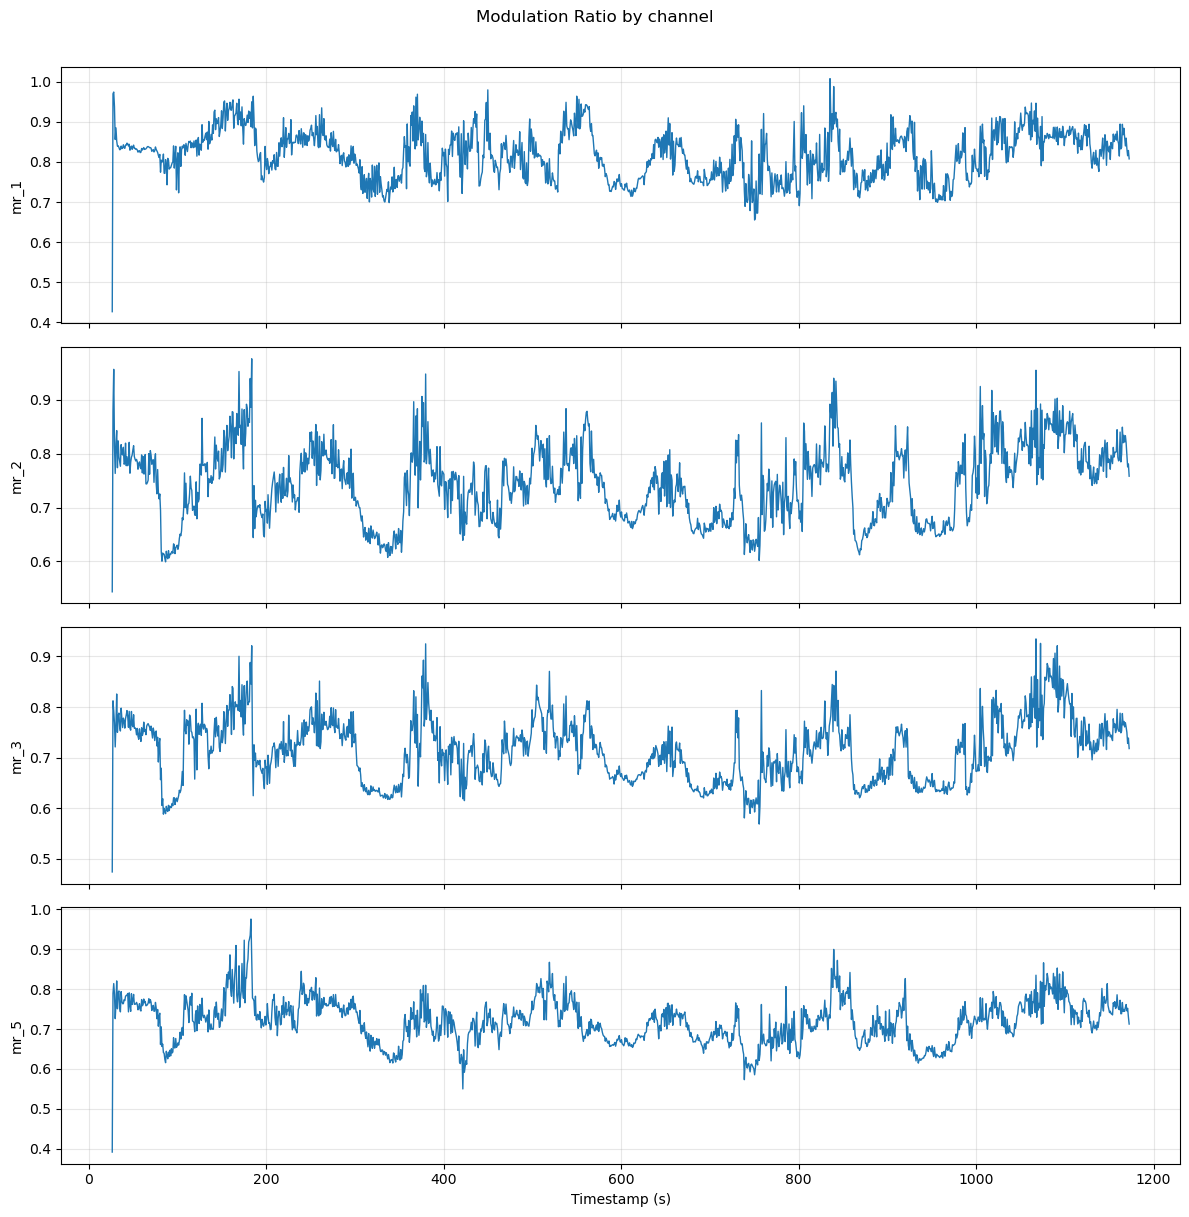

In [49]:
fig, axes = plt.subplots(len(mr_cols), 1, figsize=(12, 12), sharex=True)

for ax, col in zip(axes, mr_cols):
    ax.plot(mr_df["timestamp"], mr_df[col], linewidth=1)
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Timestamp (s)")
fig.suptitle("Modulation Ratio by channel", y=1.01)
fig.tight_layout()
plt.show()

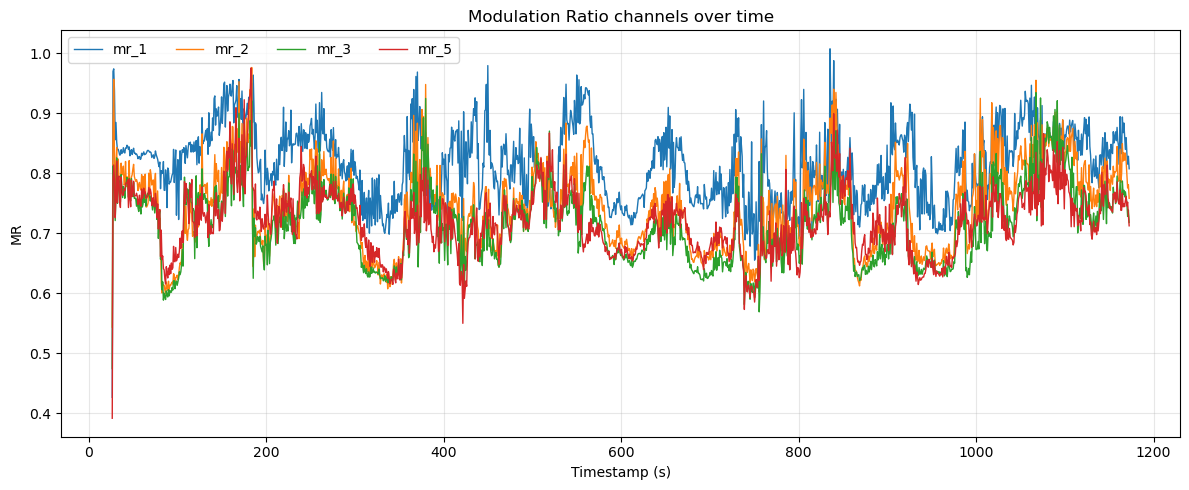

In [50]:
fig, ax = plt.subplots(figsize=(12, 5))

for col in mr_cols:
    ax.plot(mr_df["timestamp"], mr_df[col], label=col, linewidth=1)

ax.set_title("Modulation Ratio channels over time")
ax.set_xlabel("Timestamp (s)")
ax.set_ylabel("MR")
ax.grid(alpha=0.3)
ax.legend(ncol=len(mr_cols))
fig.tight_layout()
plt.show()

In [51]:
mr_correlation_df = mr_df[mr_cols].corr(method="pearson")
mr_correlation_df

,mr_1,mr_2,mr_3,mr_5
mr_1,1.000000,0.751871,0.705271,0.659976
mr_2,0.751871,1.000000,0.936568,0.801082
mr_3,0.705271,0.936568,1.000000,0.844641
mr_5,0.659976,0.801082,0.844641,1.000000


In [52]:
FHR_SAMPLE_RATE = 80.0
fhr = pd.read_csv(Path("data/patient3.csv"), usecols=["FHR"])["FHR"]
fhr_timestamp = np.arange(len(fhr)) / FHR_SAMPLE_RATE
fhr_at_mr = np.interp(mr_df["timestamp"], fhr_timestamp, fhr)

mr_fhr_correlation = (
    mr_df[mr_cols]
    .corrwith(pd.Series(fhr_at_mr, index=mr_df.index))
    .rename("pearson_r MR and FHR")
    .to_frame()
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(fhr_timestamp, fhr, color="tab:red", linewidth=0.8, label="FHR (80 Hz)")
ax.scatter(mr_df["timestamp"], fhr_at_mr, s=8, color="black", alpha=0.35, label="FHR at MR timestamps")
ax.set(title="FHR trace and MR sampling times", xlabel="Timestamp (s)", ylabel="FHR")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

mr_fhr_correlation

FileNotFoundError: [Errno 2] No such file or directory: 'data\\patient3.csv'

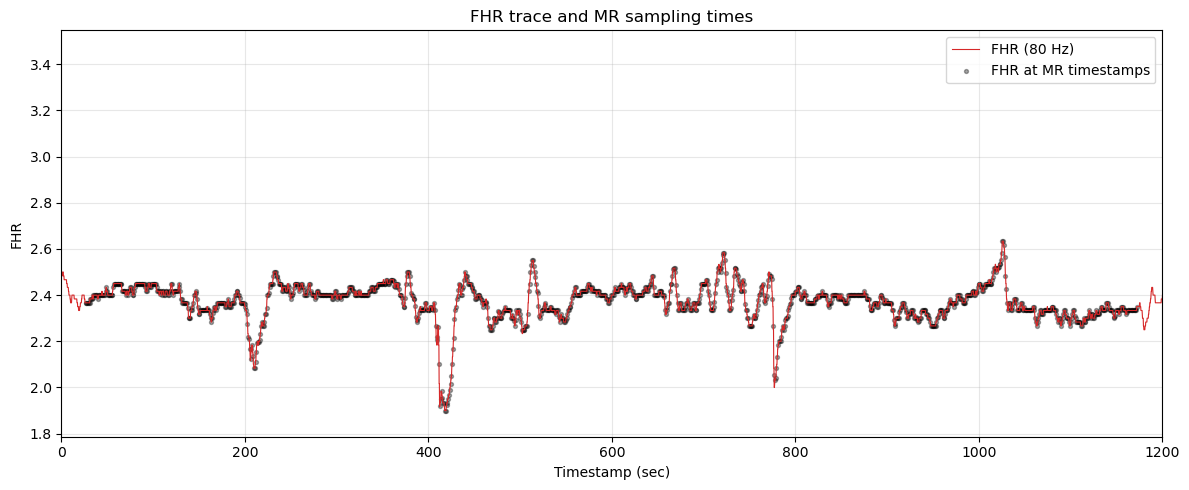

,pearson_r MR and FHR
mr_1,-0.047415
mr_2,-0.058991
mr_3,-0.058836
mr_5,0.024812


In [53]:
FHR_CSV_PATH = Path(r"F:\patient data\Intrapartum 3 07_11_24\2024-07-11_15-32-07\output 2024-07-11_15-32-07(CX250).csv")
FHR_SAMPLE_RATE = 4
fhr_table = pd.read_csv(Path(FHR_CSV_PATH))
fhr = pd.to_numeric(fhr_table.iloc[:, 1], errors="coerce").replace(0, np.nan)/60
fhr_timestamp = np.arange(len(fhr)) / FHR_SAMPLE_RATE


# Assumes the FHR and MR recordings share the same t=0.
valid_fhr = fhr.notna()
fhr_at_mr = np.interp(
    mr_df["timestamp"],
    fhr_timestamp[valid_fhr],
    fhr[valid_fhr],
)

mr_fhr_correlation = (
    mr_df[mr_cols]
    .corrwith(pd.Series(fhr_at_mr, index=mr_df.index))
    .rename("pearson_r MR and FHR")
    .to_frame()
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(fhr_timestamp, fhr, color="tab:red", linewidth=0.8, label="FHR (80 Hz)")
ax.scatter(mr_df["timestamp"], fhr_at_mr, s=8, color="black", alpha=0.35, label="FHR at MR timestamps")
ax.set(title="FHR trace and MR sampling times", xlabel="Timestamp (sec)", ylabel="FHR", xlim=(0, 1200))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

mr_fhr_correlation

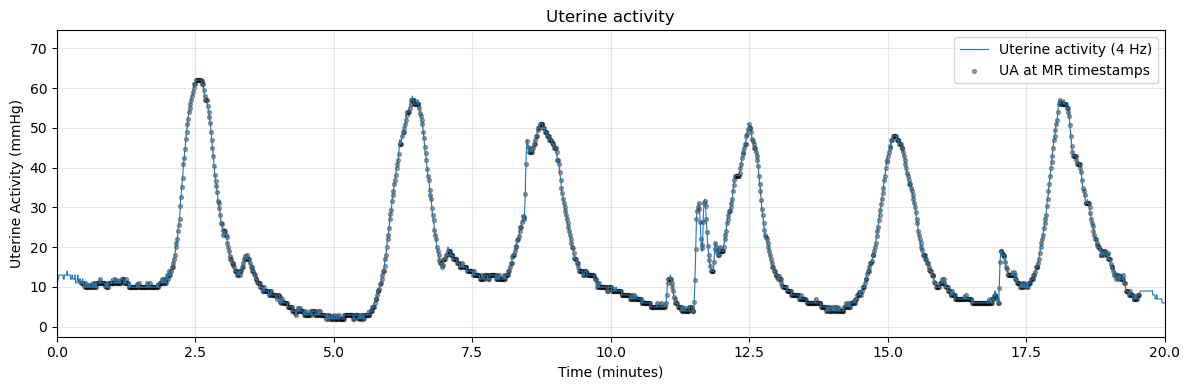

,pearson_r MR and UA
mr_1,0.219997
mr_2,0.265574
mr_3,0.281050
mr_5,0.167072


In [54]:
UTERINE_CSV_PATH = Path(r"F:\patient data\Intrapartum 3 07_11_24\2024-07-11_15-32-07\output 2024-07-11_15-32-07(CX250).csv")
UTERINE_SAMPLE_RATE = 4.0  # Hz; adjust if the CX250 export uses another rate

uterine_table = pd.read_csv(UTERINE_CSV_PATH)
uterine = pd.to_numeric(uterine_table.iloc[:, 4], errors="coerce").replace(0, np.nan)
uterine_time_seconds = np.arange(len(uterine)) / UTERINE_SAMPLE_RATE
uterine_time_minutes = uterine_time_seconds / 60

# Assumes the uterine and MR recordings share the same t=0.
valid_uterine = uterine.notna()
uterine_at_mr = np.interp(
    mr_df["timestamp"],
    uterine_time_seconds[valid_uterine],
    uterine[valid_uterine],
)
mr_uterine_correlation = (
    mr_df[mr_cols]
    .corrwith(pd.Series(uterine_at_mr, index=mr_df.index))
    .rename("pearson_r MR and UA")
    .to_frame()
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(uterine_time_minutes, uterine, linewidth=0.8, label="Uterine activity (4 Hz)")
ax.scatter(mr_df["timestamp"] / 60, uterine_at_mr, s=8, color="black", alpha=0.35, label="UA at MR timestamps")
ax.set(xlabel="Time (minutes)", ylabel="Uterine Activity (mmHg)", title="Uterine activity", xlim=(0, 20))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

mr_uterine_correlation

In [78]:
pr_smooth_df = pr_df[["timestamp"]].copy()
pr_smooth_df[pr_cols] = pr_df[pr_cols].rolling(240, center=True, min_periods=1).mean()

pr_smooth_df.head()

,timestamp,pr_1,pr_2,pr_3,pr_5
0,26.458250,0.825742,0.728789,0.718023,0.728931
1,27.295750,0.825897,0.729216,0.718380,0.729202
2,28.133250,0.826006,0.729636,0.718771,0.729221
3,28.964625,0.826033,0.729886,0.718977,0.729161
4,29.802125,0.826572,0.730983,0.719691,0.729551


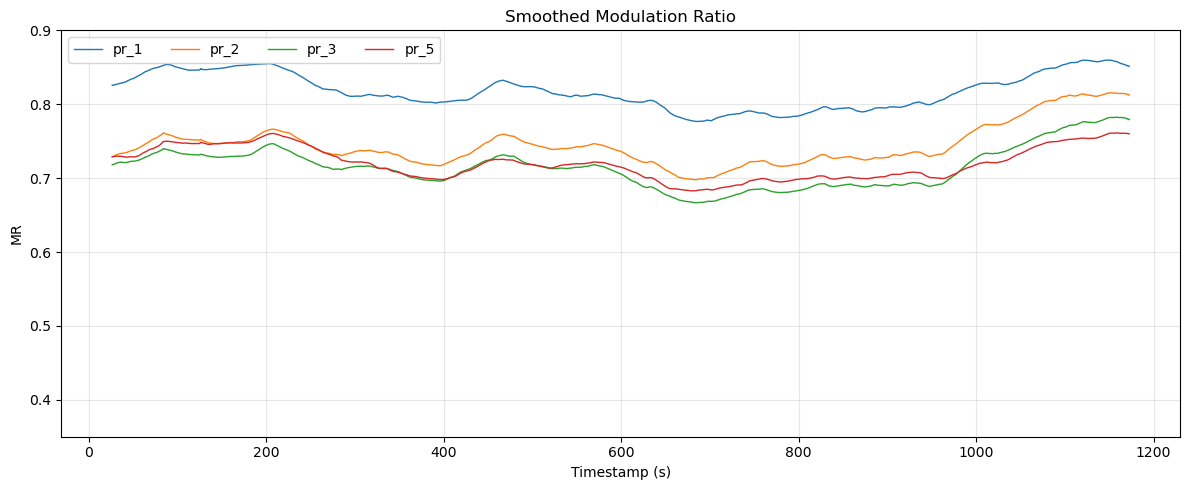

In [79]:
fig, ax = plt.subplots(figsize=(12, 5))

for col in pr_cols:
    ax.plot(pr_smooth_df["timestamp"], pr_smooth_df[col], label=col, linewidth=1)

ax.set_title("Smoothed Modulation Ratio")
ax.set_xlabel("Timestamp (s)")
ax.set_ylabel("MR")
ax.set(ylim=(0.35,0.9))
ax.grid(alpha=0.3)
ax.legend(ncol=len(pr_cols))

fig.tight_layout()
plt.show()

### PR to SpO2



In [80]:
saturation_cols = [col.replace("pr_", "saturation_") for col in pr_cols]

saturation_df = pr_df[["timestamp"]].copy()
saturation_df[saturation_cols] = compute_saturation_from_epsilon_ratio(pr_df[pr_cols].to_numpy())
saturation_smooth_df = pr_smooth_df[["timestamp"]].copy()
saturation_smooth_df[saturation_cols] = compute_saturation_from_epsilon_ratio(pr_smooth_df[pr_cols].to_numpy())

saturation_df.head()

,timestamp,saturation_1,saturation_2,saturation_3,saturation_5
0,26.458250,0.000000,0.894014,0.980678,0.000000
1,27.295750,0.451940,0.534275,0.599104,0.621940
2,28.133250,0.448173,0.463526,0.619379,0.597507
3,28.964625,0.480834,0.596587,0.643119,0.623968
4,29.802125,0.556663,0.648259,0.692257,0.687160


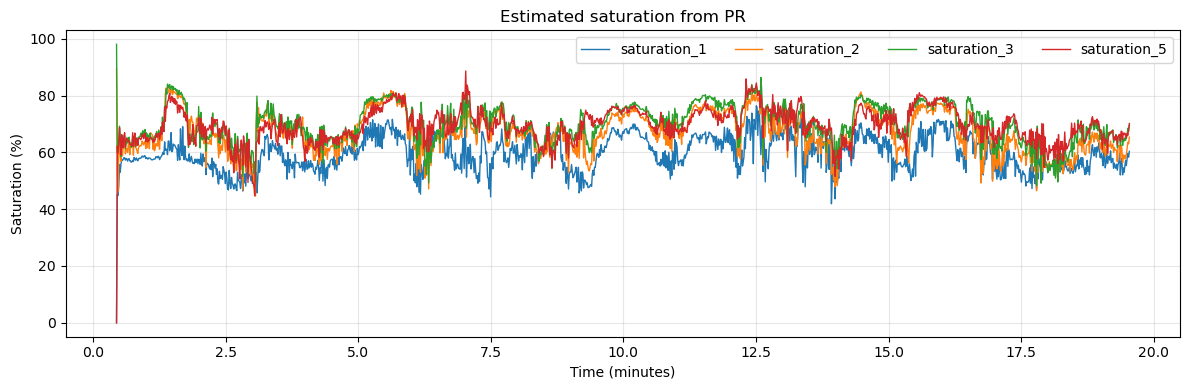

,timestamp,saturation_1,saturation_2,saturation_3,saturation_5
0,26.458250,0.000000,0.894014,0.980678,0.000000
1,27.295750,0.451940,0.534275,0.599104,0.621940
2,28.133250,0.448173,0.463526,0.619379,0.597507
3,28.964625,0.480834,0.596587,0.643119,0.623968
4,29.802125,0.556663,0.648259,0.692257,0.687160


In [71]:
fig, ax = plt.subplots(figsize=(12, 4))
for col in saturation_cols:
    ax.plot(saturation_df["timestamp"] / 60, saturation_df[col] * 100, label=col, linewidth=1)

ax.set(
    title="Estimated saturation from PR",
    xlabel="Time (minutes)",
    ylabel="Saturation (%)",
)
ax.grid(alpha=0.3)
ax.legend(ncol=len(saturation_cols))
fig.tight_layout()
plt.show()

saturation_df.head()

### Ensemble Estimates

In [ ]:
# Ensemble PR across channels with row-wise outlier rejection.
# A channel is rejected at a timestamp if it is more than 3 scaled MADs from that timestamp's median.
pr_values = pr_df[pr_cols]
pr_median = pr_values.median(axis=1)
pr_mad = pr_values.sub(pr_median, axis=0).abs().median(axis=1)
pr_robust_sigma = 1.4826 * pr_mad

pr_outlier_mask = pr_values.sub(pr_median, axis=0).abs().gt(3 * pr_robust_sigma.replace(0, np.nan), axis=0)
zero_mad_outlier_mask = pr_values.ne(pr_median, axis=0)
zero_mad_outlier_mask.loc[~pr_mad.eq(0), :] = False
pr_outlier_mask |= zero_mad_outlier_mask
pr_clean = pr_values.mask(pr_outlier_mask)

ensemble_df = pr_df[["timestamp"]].copy()
ensemble_df["ensemble_pr"] = pr_clean.mean(axis=1)
ensemble_df["n_channels_used"] = pr_clean.notna().sum(axis=1)
ensemble_df["n_channels_rejected"] = pr_outlier_mask.sum(axis=1)
ensemble_df["ensemble_saturation"] = compute_saturation_from_epsilon_ratio(
    ensemble_df["ensemble_pr"].to_numpy()
)

ensemble_df["ensemble_pr_smooth"] = ensemble_df["ensemble_pr"].rolling(10, center=True, min_periods=1).mean()
ensemble_df["ensemble_saturation_smooth"] = compute_saturation_from_epsilon_ratio(
    ensemble_df["ensemble_pr_smooth"].to_numpy()
)

print(f"Rejected {int(pr_outlier_mask.sum().sum()):,} channel-time values")
ensemble_df.head()



Rejected 603 channel-time values


,timestamp,ensemble_pr,n_channels_used,n_channels_rejected,ensemble_saturation,ensemble_pr_smooth,ensemble_saturation_smooth
0,26.458250,0.459245,4,0,0.000000,0.732834,0.680106
1,27.295750,0.862874,4,0,0.550125,0.733123,0.679803
2,28.133250,0.884317,4,0,0.529867,0.733502,0.679406
3,28.964625,0.790316,3,1,0.621088,0.733749,0.679146
4,29.802125,0.736992,3,1,0.675750,0.734573,0.678283


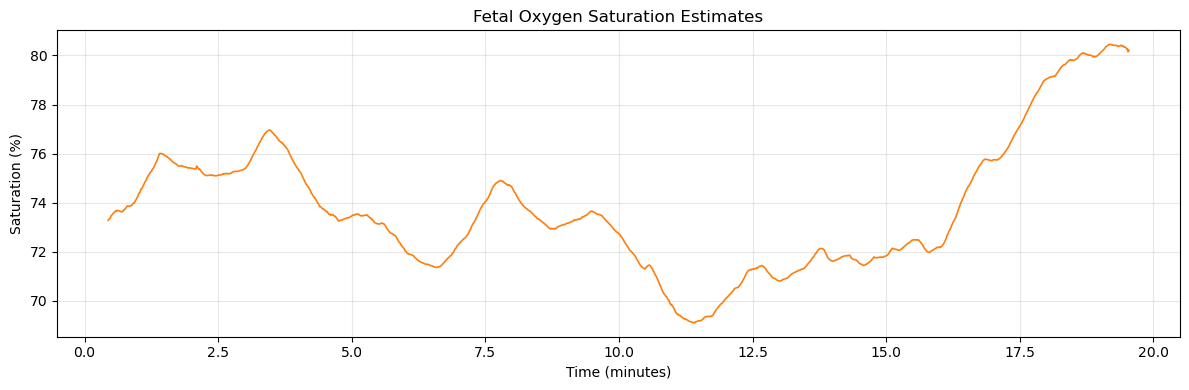

In [75]:
fig, ax_sat = plt.subplots(figsize=(12, 4))

ax_sat.plot(
    ensemble_df["timestamp"] / 60,
    ensemble_df["ensemble_pr_smooth"] * 100,
    color="tab:orange",
    linewidth=1.2,
    label="Ensemble saturation",
)


ax_sat.set(
    title="Fetal Oxygen Saturation Estimates",
    ylabel="Saturation (%)",
    xlabel="Time (minutes)",
)
ax_sat.grid(alpha=0.3)
fig.tight_layout()
plt.show()



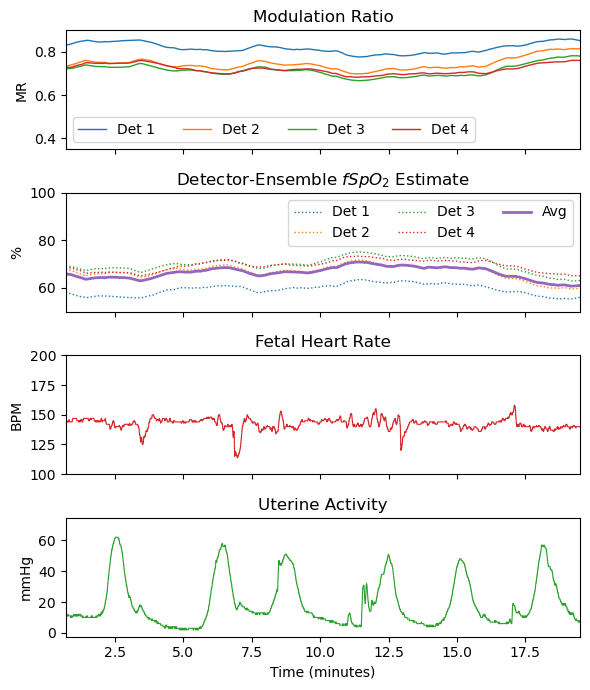

In [83]:
fig, axes = plt.subplots(4, 1, figsize=(6, 7), sharex=True)

for i,col in enumerate(pr_cols):
    axes[0].plot(pr_smooth_df["timestamp"] / 60, pr_smooth_df[col], label=f"Det {i+1}", linewidth=1)
axes[0].set(title="Modulation Ratio", ylabel="MR")
axes[0].legend(ncol=len(pr_cols))
axes[0].set(ylim=(0.35,0.9))

# methodB = pd.read_csv("data/human_fig1_pred_per_sec.csv")
# axes[1].plot(methodB["sec"] / 60,  methodB["pred_fsao2"], label="Method B", linewidth=1.2)

for i,col in enumerate(saturation_cols):
    axes[1].plot(saturation_smooth_df["timestamp"] / 60, saturation_smooth_df[col]*100, label=f"Det {i+1}", linewidth=1, linestyle=":")
axes[1].plot(saturation_smooth_df["timestamp"] / 60, saturation_smooth_df[saturation_cols].mean(axis=1) * 100, label="Avg", linewidth=2)
axes[1].set(ylim=(50,100))

# for win in [10,30,60]:
#     ensemble_pr_smooth = ensemble_df["ensemble_pr"].rolling(win, center=True, min_periods=1).mean()
#     ensemble_saturation_smooth = compute_saturation_from_epsilon_ratio(ensemble_pr_smooth.to_numpy())       
#     axes[1].plot(ensemble_df["timestamp"] / 60, ensemble_saturation_smooth * 100, label=f"{win}sec avg", linewidth=1.2)
axes[1].set(
    title="Detector-Ensemble $fSpO_2$ Estimate",
    ylabel="%",
    xlim=(0.7, 19.5),
    ylim=(50,100), 

)
axes[1].legend(ncol=3)

axes[2].plot(fhr_timestamp / 60, fhr * 60, color="tab:red", linewidth=0.8)
axes[2].set(title="Fetal Heart Rate", ylabel="BPM", ylim=(100,200))

axes[3].plot(uterine_time_seconds / 60, uterine, color="tab:green", linewidth=0.8)
axes[3].set(title="Uterine Activity", ylabel="mmHg",xlabel="Time (minutes)")


# for ax in axes:
#     ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()